# 🔐 Quantum-Enhanced Phishing URL Detector
## QSVC vs VQC vs Classical Baseline

Questo notebook confronta tre approcci di machine learning per il rilevamento di URL di phishing:
un classificatore classico (baseline), un Quantum Support Vector Classifier (QSVC) basato su kernel
quantistico, e un Variational Quantum Classifier (VQC). Lo scopo è valutare empiricamente
i vantaggi e i limiti del Quantum Machine Learning su un problema reale di cybersecurity.

In [1]:
# Verifica installazione librerie
import qiskit
import qiskit_machine_learning
import pandas as pd
import numpy as np
import matplotlib
import sklearn
import seaborn

print(f"Qiskit: {qiskit.__version__}")
print(f"Qiskit Machine Learning: {qiskit_machine_learning.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")
print(f"Seaborn: {seaborn.__version__}")
print("\nTutte le librerie sono installate correttamente!")

Qiskit: 2.4.0
Qiskit Machine Learning: 0.9.0
Pandas: 3.0.2
NumPy: 2.4.4
Matplotlib: 3.10.8
Scikit-learn: 1.8.0
Seaborn: 0.13.2

Tutte le librerie sono installate correttamente!


## 0. Caricamento Dati Salvati

Caricamento dei dati preprocessati e dei modelli già addestrati dal disco.
Eseguire questa cella all'inizio di ogni sessione per ripristinare lo stato del notebook
senza rieseguire i training costosi.

In [1]:
import pickle
import os

# Carica dati preprocessing
if os.path.exists('preprocessed_data.pkl'):
    with open('preprocessed_data.pkl', 'rb') as f:
        data = pickle.load(f)
    X_train_scaled = data['X_train_scaled']
    X_test_scaled = data['X_test_scaled']
    y_train = data['y_train']
    y_test = data['y_test']
    scaler = data['scaler']
    print("Dati preprocessati caricati dal disco!")
else:
    print("File preprocessed_data.pkl non trovato, riesegui il preprocessing")

# Carica modelli baseline
if os.path.exists('baseline_models.pkl'):
    with open('baseline_models.pkl', 'rb') as f:
        baseline_data = pickle.load(f)
    svm_classical = baseline_data['svm_model']
    lr = baseline_data['lr_model']
    rf = baseline_data['rf_model']
    results = baseline_data['results']
    y_pred_svm = baseline_data['y_pred_svm']
    y_prob_svm = baseline_data['y_prob_svm']
    y_pred_lr = baseline_data['y_pred_lr']
    y_prob_lr = baseline_data['y_prob_lr']
    y_pred_rf = baseline_data['y_pred_rf']
    y_prob_rf = baseline_data['y_prob_rf']
    print("Modelli baseline caricati dal disco!")
else:
    print("File baseline_models.pkl non trovato, riesegui la baseline")

# Carica dati QSVC
if os.path.exists('qsvc_data.pkl'):
    with open('qsvc_data.pkl', 'rb') as f:
        qsvc_data = pickle.load(f)
    X_train_qsvc = qsvc_data['X_train_qsvc']
    X_test_qsvc = qsvc_data['X_test_qsvc']
    y_train_qsvc = qsvc_data['y_train_qsvc']
    y_test_qsvc = qsvc_data['y_test_qsvc']
    y_pred_qsvc = qsvc_data['y_pred_qsvc']
    qsvc_time = qsvc_data['qsvc_time'] 
    print("Dati QSVC caricati dal disco!")
else:
    print("File qsvc_data.pkl non trovato, riesegui la cella QSVC subset")
    
# Carica risultati VQC (pesi e convergenza)
if os.path.exists('vqc_results.pkl'):
    with open('vqc_results.pkl', 'rb') as f:
        vqc_data = pickle.load(f)
    objective_values = vqc_data['objective_values']
    vqc_time = vqc_data['vqc_time']
    weights = vqc_data['weights']
    y_pred_vqc = vqc_data['y_pred_vqc']
    y_test_vqc = vqc_data['y_test_vqc']
    X_train_vqc = vqc_data['X_train_vqc']  
    X_test_vqc = vqc_data['X_test_vqc']   
    y_train_vqc = vqc_data['y_train_vqc']  
    print("Risultati VQC caricati dal disco!")
else:
    print("File vqc_results.pkl non trovato, riesegui la cella VQC")

Dati preprocessati caricati dal disco!
Modelli baseline caricati dal disco!
Dati QSVC caricati dal disco!
Risultati VQC caricati dal disco!


## 1. Dataset & Feature Engineering

Caricamento del dataset "Phishing Site URLs" (Kaggle, 549k+ URL) ed estrazione
di 5 feature di sicurezza direttamente dagli URL grezzi tramite regex e Python puro,
senza dipendenze da API esterne.

| Feature | Motivazione |
|---|---|
| URL_Length | URL lunghi sono tipici del phishing |
| Shannon_Entropy | Alta entropia indica offuscamento |
| Subdomain_Count | Molti sottodomini sono segnale di phishing |
| Special_Char_Count | Caratteri come @, -, %, = tipici del phishing |
| Digit_Ratio | Alta percentuale di cifre indica domini generati automaticamente |

In [3]:
# Caricamento dataset
df = pd.read_csv('phishing_site_urls.csv')

# Prima occhiata ai dati
print(f"Dimensioni dataset: {df.shape}")
print(f"\nColonne: {df.columns.tolist()}")
print(f"\nPrime 5 righe:")
df.head()

Dimensioni dataset: (549346, 2)

Colonne: ['URL', 'Label']

Prime 5 righe:


,URL,Label
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad
3,mail.printakid.com/www.online.americanexpress....,bad
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad


In [4]:
# Distribuzione classi
print("Distribuzione classi:")
print(df['Label'].value_counts())
print(f"\nPercentuale:")
print(df['Label'].value_counts(normalize=True).round(3) * 100)

Distribuzione classi:
Label
good    392924
bad     156422
Name: count, dtype: int64

Percentuale:
Label
good    71.5
bad     28.5
Name: proportion, dtype: float64


In [5]:
import re
from math import log2

def extract_features(url):
    """
    Estrae 5 feature di sicurezza da un URL grezzo.
    """
    # 1. URL_Length: lunghezza totale dell'URL
    url_length = len(url)
    
    # 2. Shannon_Entropy: misura la casualità/obfuscazione dell'URL
    prob = [url.count(c) / len(url) for c in set(url)]
    entropy = -sum(p * log2(p) for p in prob if p > 0)
    
    # 3. Subdomain_Count: numero di sottodomini
    try:
        domain = re.findall(r'(?:https?://)?([^/]+)', url)[0]
        subdomain_count = len(domain.split('.')) - 2
        subdomain_count = max(0, subdomain_count)
    except:
        subdomain_count = 0
    
    # 4. Special_Char_Count: numero di caratteri sospetti
    special_chars = re.findall(r'[@\-_%#=]', url)
    special_char_count = len(special_chars)
    
    # 5. Digit_Ratio: percentuale di cifre nell'URL
    digit_ratio = sum(c.isdigit() for c in url) / len(url) if len(url) > 0 else 0
    
    return {
        'URL_Length': url_length,
        'Shannon_Entropy': entropy,
        'Subdomain_Count': subdomain_count,
        'Special_Char_Count': special_char_count,
        'Digit_Ratio': digit_ratio
    }

# Test su un URL di esempio
test_url = df['URL'].iloc[0]
print(f"URL di test: {test_url}")
print(f"Feature estratte: {extract_features(test_url)}")

URL di test: nobell.it/70ffb52d079109dca5664cce6f317373782/login.SkyPe.com/en/cgi-bin/verification/login/70ffb52d079109dca5664cce6f317373/index.php?cmd=_profile-ach&outdated_page_tmpl=p/gen/failed-to-load&nav=0.5.1&login_access=1322408526
Feature estratte: {'URL_Length': 225, 'Shannon_Entropy': 5.026885996064955, 'Subdomain_Count': 0, 'Special_Char_Count': 12, 'Digit_Ratio': 0.2577777777777778}


In [6]:
from tqdm import tqdm
tqdm.pandas()

print("Estrazione feature in corso... (può richiedere qualche minuto)")

# Applica la funzione a tutto il dataset
features_df = df['URL'].progress_apply(lambda x: pd.Series(extract_features(x)))

# Aggiungi la label
features_df['Label'] = df['Label'].values

print(f"\nFeature estratte con successo!")
print(f"Dimensioni: {features_df.shape}")
print(f"\nPrime 5 righe:")
features_df.head()

Estrazione feature in corso... (può richiedere qualche minuto)


100%|████████████████████████████████████████████████████████████████████████| 549346/549346 [05:33<00:00, 1645.86it/s]


Feature estratte con successo!
Dimensioni: (549346, 6)

Prime 5 righe:


,URL_Length,Shannon_Entropy,Subdomain_Count,Special_Char_Count,Digit_Ratio,Label
0,225.0,5.026886,0.0,12.0,0.257778,bad
1,81.0,4.686883,1.0,5.0,0.012346,bad
2,177.0,4.721044,0.0,1.0,0.265537,bad
3,60.0,4.079842,1.0,0.0,0.000000,bad
4,116.0,4.608653,0.0,1.0,0.181034,bad


### 1.1 Bilanciamento e Scaling

Undersampling a 1000 campioni per classe (2000 totali) per garantire classi bilanciate.
Le feature vengono scalate in [0, π] con MinMaxScaler per compatibilità con i circuiti quantistici.

In [7]:
# Bilanciamento e campionamento
from sklearn.utils import resample

# Separa le classi
df_good = features_df[features_df['Label'] == 'good']
df_bad = features_df[features_df['Label'] == 'bad']

print(f"Campioni good: {len(df_good)}")
print(f"Campioni bad: {len(df_bad)}")

# Undersampling: prendi 1000 campioni per classe
N_SAMPLES = 1000
RANDOM_STATE = 42

df_good_sampled = resample(df_good, n_samples=N_SAMPLES, random_state=RANDOM_STATE)
df_bad_sampled = resample(df_bad, n_samples=N_SAMPLES, random_state=RANDOM_STATE)

# Unisci e mescola
df_balanced = pd.concat([df_good_sampled, df_bad_sampled])
df_balanced = df_balanced.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

# Converti label in numerico: good=0, bad=1
df_balanced['Label'] = df_balanced['Label'].map({'good': 0, 'bad': 1})

print(f"\nDataset bilanciato: {df_balanced.shape}")
print(f"Distribuzione classi:\n{df_balanced['Label'].value_counts()}")
df_balanced.head()

Campioni good: 392924
Campioni bad: 156422

Dataset bilanciato: (2000, 6)
Distribuzione classi:
Label
1    1000
0    1000
Name: count, dtype: int64


,URL_Length,Shannon_Entropy,Subdomain_Count,Special_Char_Count,Digit_Ratio,Label
0,73.0,4.495270,0.0,0.0,0.205479,1
1,43.0,4.518833,0.0,1.0,0.139535,0
2,32.0,3.983459,0.0,0.0,0.062500,1
3,26.0,3.517559,2.0,0.0,0.000000,0
4,23.0,4.142915,1.0,0.0,0.260870,1


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# Separa feature e label
X = df_balanced[['URL_Length', 'Shannon_Entropy', 'Subdomain_Count', 
                  'Special_Char_Count', 'Digit_Ratio']].values
y = df_balanced['Label'].values

# Split train/test 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scala in [0, pi] per compatibilità con i circuiti quantistici
scaler = MinMaxScaler(feature_range=(0, np.pi))
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: {X_train_scaled.shape}")
print(f"Test set: {X_test_scaled.shape}")
print(f"\nDistribuzione classi nel training set:")
print(f"  good (0): {sum(y_train == 0)}")
print(f"  bad  (1): {sum(y_train == 1)}")
print(f"\nDistribuzione classi nel test set:")
print(f"  good (0): {sum(y_test == 0)}")
print(f"  bad  (1): {sum(y_test == 1)}")
print(f"\nRange feature dopo scaling:")
print(f"  Min: {X_train_scaled.min():.4f}")
print(f"  Max: {X_train_scaled.max():.4f}")

Training set: (1600, 5)
Test set: (400, 5)

Distribuzione classi nel training set:
  good (0): 800
  bad  (1): 800

Distribuzione classi nel test set:
  good (0): 200
  bad  (1): 200

Range feature dopo scaling:
  Min: 0.0000
  Max: 3.1416


In [9]:
import pickle

# Salva dati preprocessing su disco
data_to_save = {
    'X_train_scaled': X_train_scaled,
    'X_test_scaled': X_test_scaled,
    'y_train': y_train,
    'y_test': y_test,
    'scaler': scaler
}

with open('preprocessed_data.pkl', 'wb') as f:
    pickle.dump(data_to_save, f)

print("Dati preprocessati salvati su disco!")

Dati preprocessati salvati su disco!


### 1.2 Analisi Esplorativa

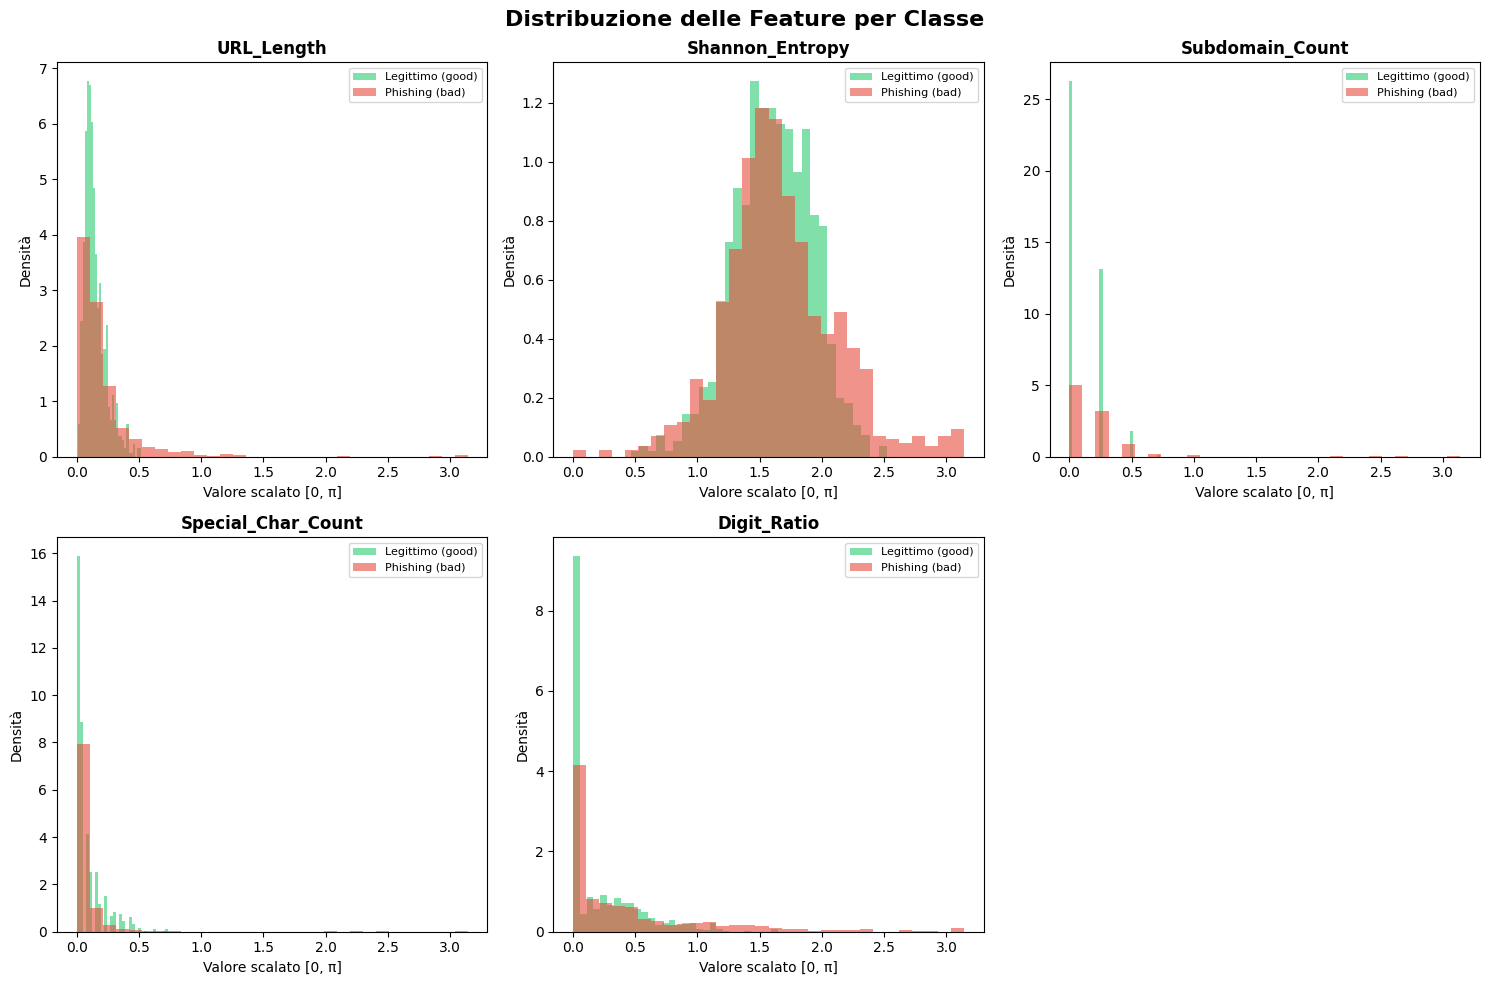

Grafico salvato come 'feature_distributions.png'


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Distribuzione delle Feature per Classe', fontsize=16, fontweight='bold')

feature_names = ['URL_Length', 'Shannon_Entropy', 'Subdomain_Count', 
                 'Special_Char_Count', 'Digit_Ratio']
colors = ['#2ecc71', '#e74c3c']
labels = ['Legittimo (good)', 'Phishing (bad)']

for idx, feature in enumerate(feature_names):
    ax = axes[idx // 3][idx % 3]
    
    for class_val, color, label in zip([0, 1], colors, labels):
        mask = y_train == class_val
        ax.hist(X_train_scaled[mask, idx], bins=30, alpha=0.6, 
                color=color, label=label, density=True)
    
    ax.set_title(feature, fontweight='bold')
    ax.set_xlabel('Valore scalato [0, π]')
    ax.set_ylabel('Densità')
    ax.legend(fontsize=8)

# Nascondi l'ultimo subplot vuoto
axes[1][2].axis('off')

plt.tight_layout()
plt.savefig('feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafico salvato come 'feature_distributions.png'")

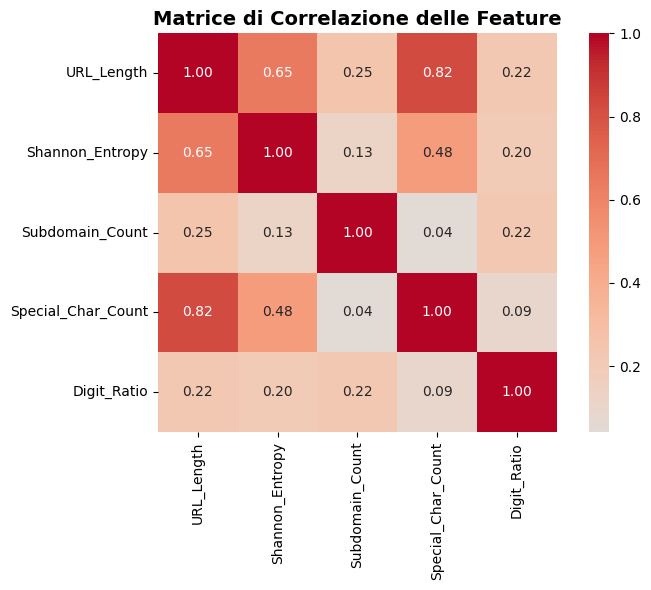

Grafico salvato come 'correlation_matrix.png'


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Heatmap correlazione
fig, ax = plt.subplots(figsize=(8, 6))

feature_df_plot = pd.DataFrame(X_train_scaled, columns=feature_names)
correlation_matrix = feature_df_plot.corr()

sns.heatmap(correlation_matrix, 
            annot=True, 
            fmt='.2f',
            cmap='coolwarm',
            center=0,
            square=True,
            ax=ax)

ax.set_title('Matrice di Correlazione delle Feature', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafico salvato come 'correlation_matrix.png'")

## 2. Baseline Classica

Training di tre classificatori classici come baseline di riferimento:
SVM con kernel RBF, Logistic Regression e Random Forest.
Metriche valutate: Accuracy, F1-Score, ROC-AUC, tempo di training.

In [12]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report
import time

print("=" * 50)
print("BASELINE CLASSICA - SVM con kernel RBF")
print("=" * 50)

# Training
start_time = time.time()
svm_classical = SVC(kernel='rbf', probability=True, random_state=42)
svm_classical.fit(X_train_scaled, y_train)
training_time = time.time() - start_time

# Predizioni
y_pred_svm = svm_classical.predict(X_test_scaled)
y_prob_svm = svm_classical.predict_proba(X_test_scaled)[:, 1]

# Metriche
acc_svm = accuracy_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)
roc_svm = roc_auc_score(y_test, y_prob_svm)

print(f"\nTempo di training: {training_time:.2f} secondi")
print(f"Accuracy:  {acc_svm:.4f}")
print(f"F1-Score:  {f1_svm:.4f}")
print(f"ROC-AUC:   {roc_svm:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_svm, 
      target_names=['Legittimo', 'Phishing']))

BASELINE CLASSICA - SVM con kernel RBF

Tempo di training: 0.63 secondi
Accuracy:  0.6150
F1-Score:  0.4934
ROC-AUC:   0.6964

Classification Report:
              precision    recall  f1-score   support

   Legittimo       0.58      0.85      0.69       200
    Phishing       0.72      0.38      0.49       200

    accuracy                           0.61       400
   macro avg       0.65      0.61      0.59       400
weighted avg       0.65      0.61      0.59       400



In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# Dizionario per salvare tutti i risultati
results = {}

# Salva risultati SVM
results['SVM (RBF)'] = {
    'accuracy': acc_svm,
    'f1': f1_svm,
    'roc_auc': roc_svm,
    'time': training_time
}

# Logistic Regression
start_time = time.time()
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_scaled, y_train)
lr_time = time.time() - start_time

y_pred_lr = lr.predict(X_test_scaled)
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]

results['Logistic Regression'] = {
    'accuracy': accuracy_score(y_test, y_pred_lr),
    'f1': f1_score(y_test, y_pred_lr),
    'roc_auc': roc_auc_score(y_test, y_prob_lr),
    'time': lr_time
}

# Random Forest
start_time = time.time()
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)
rf_time = time.time() - start_time

y_pred_rf = rf.predict(X_test_scaled)
y_prob_rf = rf.predict_proba(X_test_scaled)[:, 1]

results['Random Forest'] = {
    'accuracy': accuracy_score(y_test, y_pred_rf),
    'f1': f1_score(y_test, y_pred_rf),
    'roc_auc': roc_auc_score(y_test, y_prob_rf),
    'time': rf_time
}

# Stampa risultati
print("=" * 60)
print("RISULTATI BASELINE CLASSICA")
print("=" * 60)
print(f"{'Modello':<25} {'Accuracy':>10} {'F1':>10} {'ROC-AUC':>10} {'Tempo(s)':>10}")
print("-" * 60)
for name, res in results.items():
    print(f"{name:<25} {res['accuracy']:>10.4f} {res['f1']:>10.4f} {res['roc_auc']:>10.4f} {res['time']:>10.2f}")

RISULTATI BASELINE CLASSICA
Modello                     Accuracy         F1    ROC-AUC   Tempo(s)
------------------------------------------------------------
SVM (RBF)                     0.6150     0.4934     0.6964       0.63
Logistic Regression           0.5825     0.5296     0.6350       0.03
Random Forest                 0.6925     0.7007     0.7860       0.43


In [20]:
import pickle

# Salva modelli baseline
baseline_data = {
    'svm_model': svm_classical,
    'lr_model': lr,
    'rf_model': rf,
    'results': results,
    'y_pred_svm': y_pred_svm,
    'y_prob_svm': y_prob_svm,
    'y_pred_lr': y_pred_lr,
    'y_prob_lr': y_prob_lr,
    'y_pred_rf': y_pred_rf,
    'y_prob_rf': y_prob_rf
}

with open('baseline_models.pkl', 'wb') as f:
    pickle.dump(baseline_data, f)

print("Modelli baseline salvati su disco!")

Modelli baseline salvati su disco!


## 3. Quantum Kernel — QSVC

Classificatore basato su kernel quantistico tramite ZZFeatureMap e FidelityQuantumKernel.
Il kernel quantistico mappa i dati in uno spazio di Hilbert esponenzialmente grande,
dove una separazione lineare corrisponde a una separazione non lineare nello spazio originale.

- **Feature map:** ZZFeatureMap(feature_dimension=5, reps=2, entanglement='linear')
- **Campioni training:** 200 (100 per classe) — limitati dalla complessità O(N²) della kernel matrix

QUANTUM KERNEL - QSVC con ZZFeatureMap

Feature Map:
  Qubits: 5
  Reps: 2
  Entanglement: linear


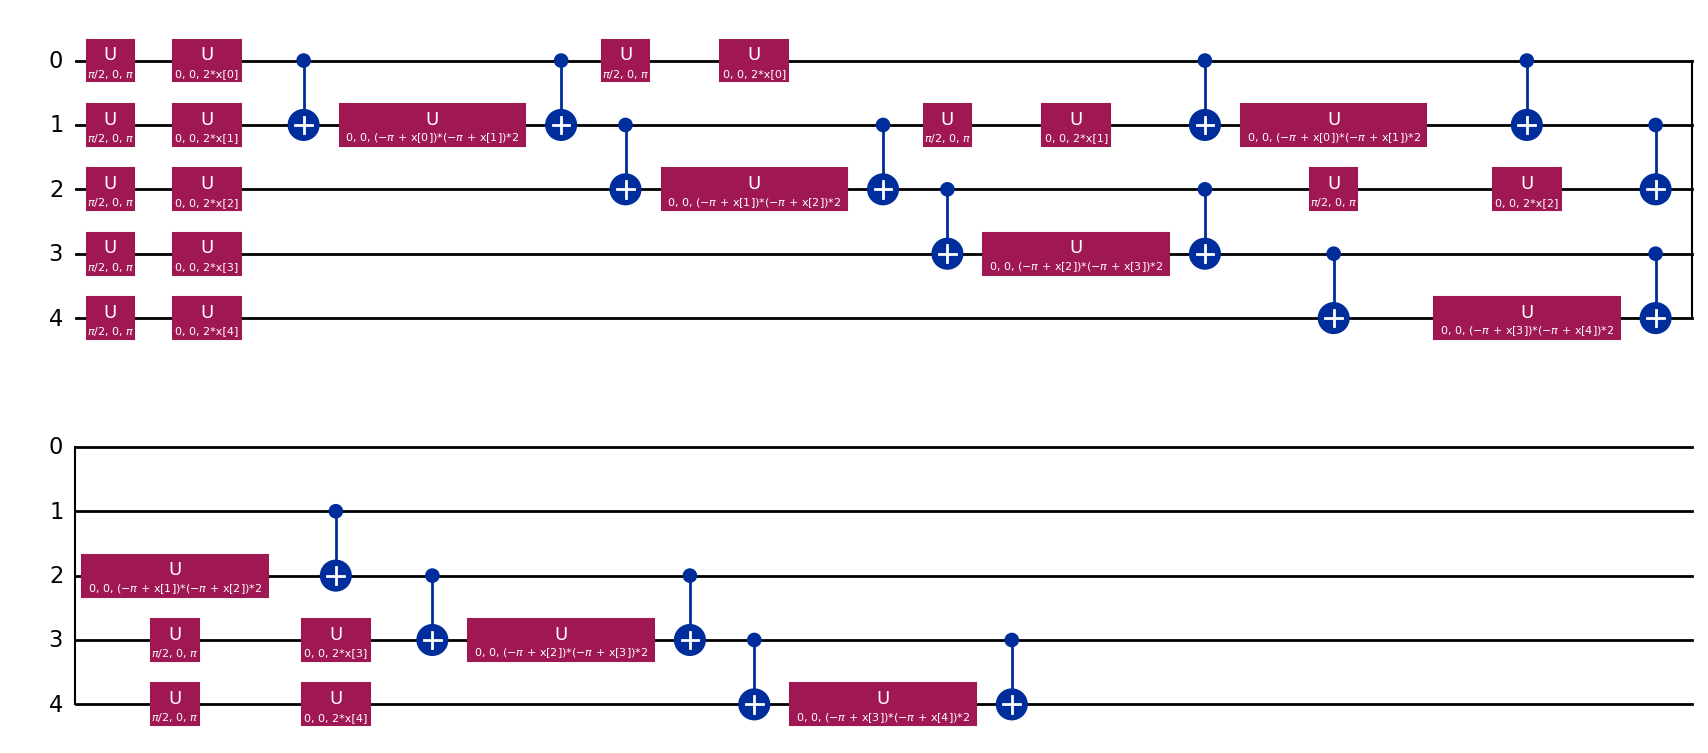

Circuito salvato come 'zz_feature_map_circuit.png'


In [4]:
import matplotlib.pyplot as plt
from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.algorithms import QSVC
from qiskit.primitives import StatevectorSampler as Sampler

print("=" * 50)
print("QUANTUM KERNEL - QSVC con ZZFeatureMap")
print("=" * 50)

# Definizione feature map con la nuova API
feature_map = zz_feature_map(
    feature_dimension=5,
    reps=2,              
    entanglement='linear'  
)

print(f"\nFeature Map:")
print(f"  Qubits: {feature_map.num_qubits}")
print(f"  Reps: 2")
print(f"  Entanglement: linear")

# Visualizza e salva il circuito
fig = feature_map.decompose().draw('mpl')
fig.savefig('zz_feature_map_circuit.png', dpi=150, bbox_inches='tight')
display(fig)
print("Circuito salvato come 'zz_feature_map_circuit.png'")

In [5]:
import time
import numpy as np
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.algorithms import QSVC
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

# Subset ridotto SOLO per QSVC
N_QSVC = 200  # 100 per classe
np.random.seed(42)
idx_good = np.where(y_train == 0)[0]
idx_bad  = np.where(y_train == 1)[0]
np.random.shuffle(idx_good)
np.random.shuffle(idx_bad)
idx_qsvc = np.concatenate([idx_good[:100], idx_bad[:100]])

X_train_qsvc = X_train_scaled[idx_qsvc]
y_train_qsvc = y_train[idx_qsvc]

idx_good_test = np.where(y_test == 0)[0]
idx_bad_test  = np.where(y_test == 1)[0]
np.random.shuffle(idx_good_test)
np.random.shuffle(idx_bad_test)
idx_qsvc_test = np.concatenate([idx_good_test[:50], idx_bad_test[:50]])

X_test_qsvc = X_test_scaled[idx_qsvc_test]
y_test_qsvc = y_test[idx_qsvc_test]

print(f"Training set QSVC: {X_train_qsvc.shape}")
print(f"Test set QSVC: {X_test_qsvc.shape}")
print("Avvio training QSVC...")

quantum_kernel = FidelityQuantumKernel(feature_map=feature_map)

start_time = time.time()
qsvc = QSVC(quantum_kernel=quantum_kernel)
qsvc.fit(X_train_qsvc, y_train_qsvc)
qsvc_training_time = time.time() - start_time

y_pred_qsvc = qsvc.predict(X_test_qsvc)

acc_qsvc = accuracy_score(y_test_qsvc, y_pred_qsvc)
f1_qsvc = f1_score(y_test_qsvc, y_pred_qsvc)
roc_qsvc = roc_auc_score(y_test_qsvc, y_pred_qsvc)

print(f"\nTempo di training: {qsvc_training_time:.2f} secondi")
print(f"Accuracy:  {acc_qsvc:.4f}")
print(f"F1-Score:  {f1_qsvc:.4f}")
print(f"ROC-AUC:   {roc_qsvc:.4f}")
print(classification_report(y_test_qsvc, y_pred_qsvc,
      target_names=['Legittimo', 'Phishing']))

Training set QSVC: (200, 5)
Test set QSVC: (100, 5)
Avvio training QSVC...

Tempo di training: 592.31 secondi
Accuracy:  0.5400
F1-Score:  0.4651
ROC-AUC:   0.5400
              precision    recall  f1-score   support

   Legittimo       0.53      0.68      0.60        50
    Phishing       0.56      0.40      0.47        50

    accuracy                           0.54       100
   macro avg       0.54      0.54      0.53       100
weighted avg       0.54      0.54      0.53       100



In [6]:
import pickle

# Salva subset QSVC su disco
qsvc_data = {
    'X_train_qsvc': X_train_qsvc,
    'X_test_qsvc': X_test_qsvc,
    'y_train_qsvc': y_train_qsvc,
    'y_test_qsvc': y_test_qsvc,
    'y_pred_qsvc': y_pred_qsvc,
    'qsvc_time': qsvc_training_time
}
with open('qsvc_data.pkl', 'wb') as f:
    pickle.dump(qsvc_data, f)

# Salva anche il modello addestrato
with open('qsvc_model.pkl', 'wb') as f:
    pickle.dump(qsvc, f)

print("Dati e modello QSVC salvati su disco!")

Dati e modello QSVC salvati su disco!


### 3.1 Analisi della Kernel Matrix

Confronto visivo tra la kernel matrix quantistica e quella classica RBF su 30 campioni.

Calcolo kernel matrix (subset 30 campioni)...


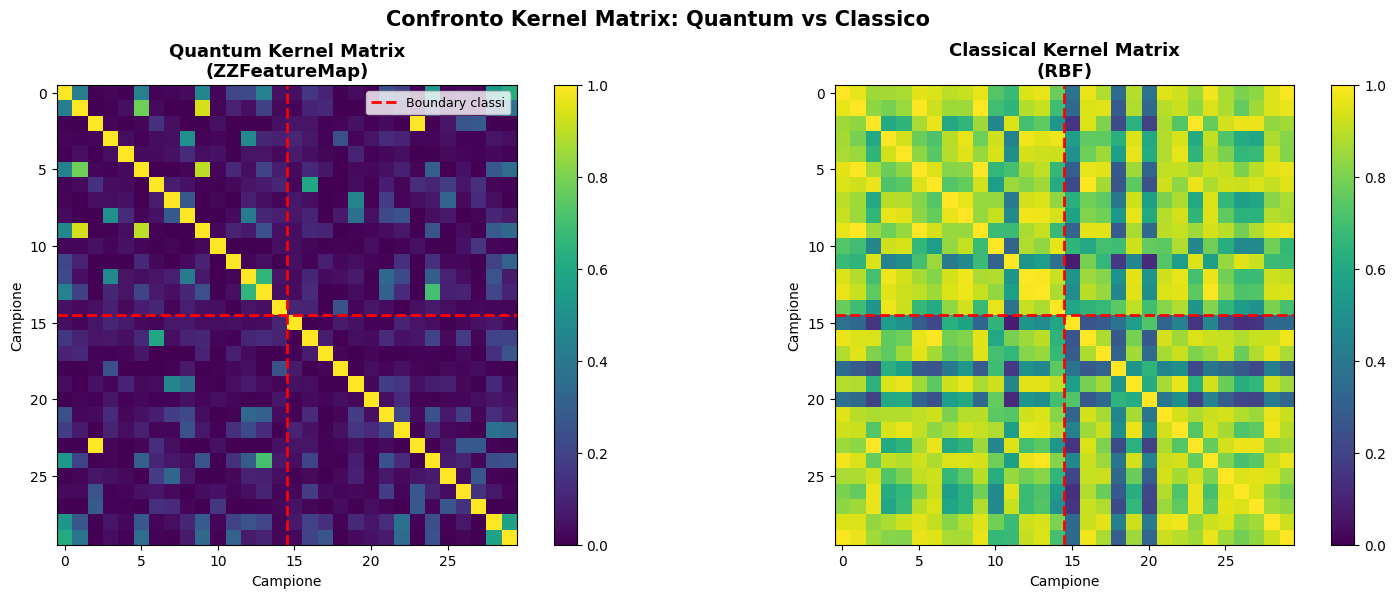

Grafico salvato come 'kernel_matrix_comparison.png'


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit.circuit.library import zz_feature_map

print("Calcolo kernel matrix (subset 30 campioni)...")

# Usa solo 30 campioni per rendere la heatmap leggibile
N_HEATMAP = 30
X_heatmap = np.concatenate([
    X_train_qsvc[y_train_qsvc == 0][:15],
    X_train_qsvc[y_train_qsvc == 1][:15]
])
y_heatmap = np.array([0]*15 + [1]*15)

# Ricalcola kernel matrix
feature_map_vis = zz_feature_map(feature_dimension=5, reps=2, entanglement='linear')
kernel_vis = FidelityQuantumKernel(feature_map=feature_map_vis)
kernel_matrix = kernel_vis.evaluate(X_heatmap)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Quantum kernel matrix
im1 = axes[0].imshow(kernel_matrix, cmap='viridis', vmin=0, vmax=1)
axes[0].set_title('Quantum Kernel Matrix\n(ZZFeatureMap)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Campione')
axes[0].set_ylabel('Campione')
plt.colorbar(im1, ax=axes[0])

# Aggiungi linea divisoria tra le classi
axes[0].axhline(y=14.5, color='red', linewidth=2, linestyle='--', label='Boundary classi')
axes[0].axvline(x=14.5, color='red', linewidth=2, linestyle='--')
axes[0].legend(fontsize=9)

# Kernel classico RBF per confronto
from sklearn.metrics.pairwise import rbf_kernel
gamma = 1.0 / (5 * X_heatmap.var())
classical_kernel = rbf_kernel(X_heatmap, gamma=gamma)

im2 = axes[1].imshow(classical_kernel, cmap='viridis', vmin=0, vmax=1)
axes[1].set_title('Classical Kernel Matrix\n(RBF)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Campione')
axes[1].set_ylabel('Campione')
plt.colorbar(im2, ax=axes[1])
axes[1].axhline(y=14.5, color='red', linewidth=2, linestyle='--')
axes[1].axvline(x=14.5, color='red', linewidth=2, linestyle='--')

plt.suptitle('Confronto Kernel Matrix: Quantum vs Classico', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('kernel_matrix_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafico salvato come 'kernel_matrix_comparison.png'")

## 4. Variational Quantum Classifier — VQC

Classificatore variazionale che ottimizza i parametri di un circuito quantistico ansatz
tramite ottimizzatore classico COBYLA. A differenza del QSVC, il VQC scala linearmente
con il numero di campioni O(N × iterazioni), permettendo l'uso di un subset più grande.

- **Feature map:** ZZFeatureMap(feature_dimension=5, reps=2, entanglement='linear')
- **Ansatz:** RealAmplitudes(num_qubits=5, reps=2, entanglement='linear') — 15 parametri
- **Ottimizzatore:** COBYLA(maxiter=200)
- **Campioni training:** 300 (150 per classe)

In [7]:
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.optimizers import COBYLA
import time
import numpy as np

print("=" * 50)
print("VQC - Variational Quantum Classifier")
print("=" * 50)

# Subset VQC — leggermente più grande del QSVC
N_VQC = 300 #150 per classe
np.random.seed(42)

idx_good = np.where(y_train == 0)[0]
idx_bad  = np.where(y_train == 1)[0]
np.random.shuffle(idx_good)
np.random.shuffle(idx_bad)

X_train_vqc = X_train_scaled[np.concatenate([idx_good[:150], idx_bad[:150]])]
y_train_vqc = y_train[np.concatenate([idx_good[:150], idx_bad[:150]])]

idx_good_test = np.where(y_test == 0)[0]
idx_bad_test  = np.where(y_test == 1)[0]
np.random.shuffle(idx_good_test)
np.random.shuffle(idx_bad_test)

X_test_vqc = X_test_scaled[np.concatenate([idx_good_test[:50], idx_bad_test[:50]])]
y_test_vqc = y_test[np.concatenate([idx_good_test[:50], idx_bad_test[:50]])]

print(f"Training set VQC: {X_train_vqc.shape}")
print(f"Test set VQC: {X_test_vqc.shape}")

# Callback per curva di convergenza
objective_values = []
def callback(weights, obj_value):
    objective_values.append(obj_value)
    if len(objective_values) % 10 == 0:
        print(f"  Iterazione {len(objective_values)}: loss = {obj_value:.4f}")

# Definizione circuito
feature_map = zz_feature_map(feature_dimension=5, reps=2, entanglement='linear')
ansatz = real_amplitudes(num_qubits=5, reps=2, entanglement='linear')

print(f"\nParametri ansatz: {ansatz.num_parameters}")

# Training
vqc = VQC(
    feature_map=feature_map,
    ansatz=ansatz,
    optimizer=COBYLA(maxiter=200),
    callback=callback
)

start_time = time.time()
vqc.fit(X_train_vqc, y_train_vqc)
vqc_time = time.time() - start_time

# Risultati
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report

y_pred_vqc = vqc.predict(X_test_vqc)

print(f"\nTempo di training: {vqc_time:.2f} secondi")
print(f"Accuracy:  {accuracy_score(y_test_vqc, y_pred_vqc):.4f}")
print(f"F1-Score:  {f1_score(y_test_vqc, y_pred_vqc):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test_vqc, y_pred_vqc):.4f}")
print(classification_report(y_test_vqc, y_pred_vqc,
      target_names=['Legittimo', 'Phishing']))

No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


VQC - Variational Quantum Classifier
Training set VQC: (300, 5)
Test set VQC: (100, 5)

Parametri ansatz: 15
  Iterazione 10: loss = 1.0463
  Iterazione 20: loss = 1.0548
  Iterazione 30: loss = 1.0369
  Iterazione 40: loss = 1.0318
  Iterazione 50: loss = 1.0278
  Iterazione 60: loss = 1.0189
  Iterazione 70: loss = 1.0003
  Iterazione 80: loss = 0.9905
  Iterazione 90: loss = 0.9738
  Iterazione 100: loss = 0.9713
  Iterazione 110: loss = 0.9651
  Iterazione 120: loss = 0.9618
  Iterazione 130: loss = 0.9589
  Iterazione 140: loss = 0.9567
  Iterazione 150: loss = 0.9566
  Iterazione 160: loss = 0.9562
  Iterazione 170: loss = 0.9560
  Iterazione 180: loss = 0.9559
  Iterazione 190: loss = 0.9559
  Iterazione 200: loss = 0.9558

Tempo di training: 849.02 secondi
Accuracy:  0.5100
F1-Score:  0.3797
ROC-AUC:   0.5100
              precision    recall  f1-score   support

   Legittimo       0.51      0.72      0.60        50
    Phishing       0.52      0.30      0.38        50

    acc

In [8]:
import pickle

# Salva pesi e risultati VQC
vqc_save = {
    'weights': vqc.weights,
    'objective_values': objective_values,
    'vqc_time': vqc_time,
    'y_pred_vqc': y_pred_vqc, 
    'y_test_vqc': y_test_vqc,
    'X_train_vqc': X_train_vqc, 
    'X_test_vqc': X_test_vqc,    
    'y_train_vqc': y_train_vqc
}
with open('vqc_results.pkl', 'wb') as f:
    pickle.dump(vqc_save, f)
print("Risultati VQC salvati!")

Risultati VQC salvati!


### 4.1 Curva di Convergenza

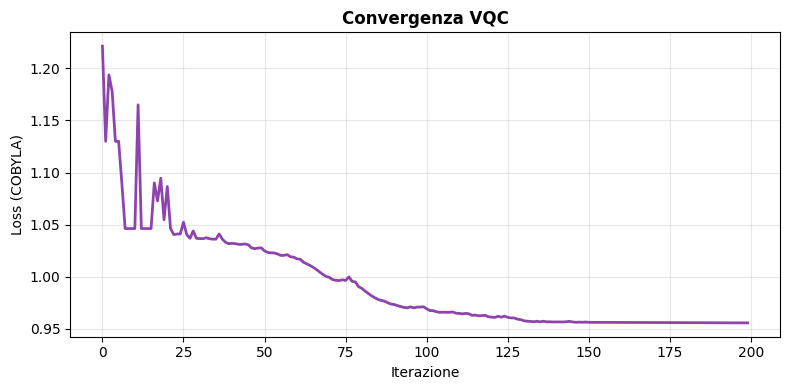

Iterazioni totali: 200
Convergenza salvata come 'vqc_convergence.png'


In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Curva di convergenza
plt.figure(figsize=(8, 4))
plt.plot(objective_values, color='#8e44ad', linewidth=2)
plt.xlabel('Iterazione')
plt.ylabel('Loss (COBYLA)')
plt.title('Convergenza VQC', fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('vqc_convergence.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Iterazioni totali: {len(objective_values)}")
print("Convergenza salvata come 'vqc_convergence.png'")

## 5. Analisi Comparativa

Confronto delle ROC curves e delle metriche di tutti i modelli.

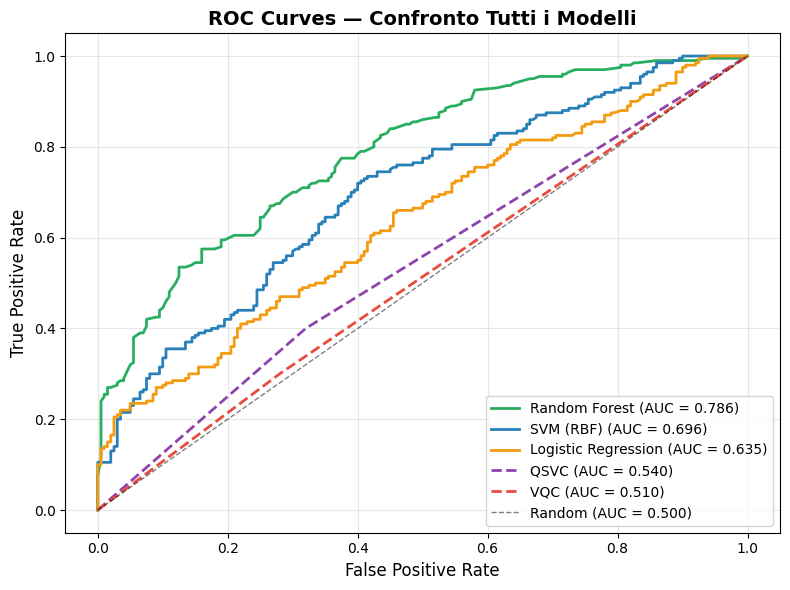

Grafico salvato come 'roc_curves_comparison.png'


In [10]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

# Modelli classici con predict_proba
modelli = {
    'Random Forest': y_prob_rf,
    'SVM (RBF)': y_prob_svm,
    'Logistic Regression': y_prob_lr,
}
colori = ['#27ae60', '#2980b9', '#f39c12']

for (nome, y_prob), colore in zip(modelli.items(), colori):
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=colore, linewidth=2, label=f'{nome} (AUC = {roc_auc:.3f})')

# QSVC e VQC con label binari (no probabilità)
for nome, y_pred, y_true, colore in [
    ('QSVC', y_pred_qsvc, y_test_qsvc, '#8e44ad'),
    ('VQC', y_pred_vqc, y_test_vqc, '#e74c3c')
]:
    fpr, tpr, _ = roc_curve(y_true, y_pred)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=colore, linewidth=2, 
            linestyle='--', label=f'{nome} (AUC = {roc_auc:.3f})')

# Linea random
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.5, label='Random (AUC = 0.500)')

ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — Confronto Tutti i Modelli', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curves_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafico salvato come 'roc_curves_comparison.png'")

### 5.1 Tabella Riassuntiva

In [11]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import pandas as pd

summary = {
    'Modello': ['Random Forest', 'SVM (RBF)', 'Logistic Regression', 'QSVC', 'VQC'],
    'Accuracy': [
        results['Random Forest']['accuracy'],
        results['SVM (RBF)']['accuracy'],
        results['Logistic Regression']['accuracy'],
        accuracy_score(y_test_qsvc, y_pred_qsvc),
        accuracy_score(y_test_vqc, y_pred_vqc)
    ],
    'F1-Score': [
        results['Random Forest']['f1'],
        results['SVM (RBF)']['f1'],
        results['Logistic Regression']['f1'],
        f1_score(y_test_qsvc, y_pred_qsvc),
        f1_score(y_test_vqc, y_pred_vqc)
    ],
    'ROC-AUC': [
        results['Random Forest']['roc_auc'],
        results['SVM (RBF)']['roc_auc'],
        results['Logistic Regression']['roc_auc'],
        roc_auc_score(y_test_qsvc, y_pred_qsvc),
        roc_auc_score(y_test_vqc, y_pred_vqc)
    ],
    'Tempo (s)': [
        results['Random Forest']['time'],
        results['SVM (RBF)']['time'],
        results['Logistic Regression']['time'],
        qsvc_time,
        vqc_time
    ],
    'Campioni train': [1600, 1600, 1600, 200, 300]
}

df_summary = pd.DataFrame(summary)
df_summary = df_summary.sort_values('ROC-AUC', ascending=False).reset_index(drop=True)

print("=" * 75)
print("TABELLA COMPARATIVA FINALE")
print("=" * 75)
print(df_summary.to_string(index=False))

df_summary.to_csv('risultati_finali.csv', index=False)
print("\nTabella salvata come 'risultati_finali.csv'")

TABELLA COMPARATIVA FINALE
            Modello  Accuracy  F1-Score  ROC-AUC  Tempo (s)  Campioni train
      Random Forest    0.6925  0.700730 0.785962   0.431122            1600
          SVM (RBF)    0.6150  0.493421 0.696375   0.634737            1600
Logistic Regression    0.5825  0.529577 0.635000   0.028882            1600
               QSVC    0.5400  0.465116 0.540000 592.308183             200
                VQC    0.5100  0.379747 0.510000 849.022773             300

Tabella salvata come 'risultati_finali.csv'


## 6. Ablation Study

Analisi sistematica dell'impatto delle configurazioni della feature map su QSVC e VQC.
Vengono testate 4 combinazioni di `reps` ed `entanglement` mantenendo fisso l'ansatz,
per valutare il trade-off tra espressività del circuito, tempo di training e performance.

In [5]:
import time
import numpy as np
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.algorithms import QSVC, VQC
from qiskit_machine_learning.optimizers import COBYLA
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

configs = [
    {'reps': 1, 'entanglement': 'linear',   'label': 'reps=1, linear'},
    {'reps': 2, 'entanglement': 'linear',   'label': 'reps=2, linear'},
    {'reps': 2, 'entanglement': 'circular', 'label': 'reps=2, circular'},
    {'reps': 2, 'entanglement': 'full',     'label': 'reps=2, full'},
]

ablation_results = []

for cfg in configs:
    print(f"\n{'='*50}")
    print(f"Configurazione: {cfg['label']}")
    
    fm = zz_feature_map(
        feature_dimension=5,
        reps=cfg['reps'],
        entanglement=cfg['entanglement']
    )
    
    # --- QSVC ---
    print("  QSVC in corso...")
    kernel = FidelityQuantumKernel(feature_map=fm)
    qsvc_abl = QSVC(quantum_kernel=kernel)
    start = time.time()
    qsvc_abl.fit(X_train_qsvc, y_train_qsvc)
    qsvc_abl_time = time.time() - start
    y_pred_qsvc_abl = qsvc_abl.predict(X_test_qsvc)
    print(f"  QSVC done — Accuracy: {accuracy_score(y_test_qsvc, y_pred_qsvc_abl):.4f} | Tempo: {qsvc_abl_time:.1f}s")

    # --- VQC ---
    print("  VQC in corso...")
    ans = real_amplitudes(num_qubits=5, reps=2, entanglement='linear')
    vqc_abl = VQC(
        feature_map=fm,
        ansatz=ans,
        optimizer=COBYLA(maxiter=100),
    )
    start = time.time()
    vqc_abl.fit(X_train_vqc, y_train_vqc)
    vqc_abl_time = time.time() - start
    y_pred_vqc_abl = vqc_abl.predict(X_test_vqc)
    print(f"  VQC done — Accuracy: {accuracy_score(y_test_vqc, y_pred_vqc_abl):.4f} | Tempo: {vqc_abl_time:.1f}s")

    ablation_results.append({
        'Configurazione': cfg['label'],
        'QSVC Accuracy': round(accuracy_score(y_test_qsvc, y_pred_qsvc_abl), 4),
        'QSVC F1': round(f1_score(y_test_qsvc, y_pred_qsvc_abl), 4),
        'QSVC Tempo (s)': round(qsvc_abl_time, 1),
        'VQC Accuracy': round(accuracy_score(y_test_vqc, y_pred_vqc_abl), 4),
        'VQC F1': round(f1_score(y_test_vqc, y_pred_vqc_abl), 4),
        'VQC Tempo (s)': round(vqc_abl_time, 1),
    })

df_ablation = pd.DataFrame(ablation_results)
print("\n" + "=" * 80)
print("ABLATION STUDY")
print("=" * 80)
print(df_ablation.to_string(index=False))
df_ablation.to_csv('ablation_study.csv', index=False)
print("\nSalvato come 'ablation_study.csv'")


Configurazione: reps=1, linear
  QSVC in corso...


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


  QSVC done — Accuracy: 0.5800 | Tempo: 432.6s
  VQC in corso...
  VQC done — Accuracy: 0.5300 | Tempo: 488.6s

Configurazione: reps=2, linear
  QSVC in corso...


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


  QSVC done — Accuracy: 0.5400 | Tempo: 606.0s
  VQC in corso...
  VQC done — Accuracy: 0.5400 | Tempo: 583.6s

Configurazione: reps=2, circular
  QSVC in corso...


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


  QSVC done — Accuracy: 0.5900 | Tempo: 641.4s
  VQC in corso...
  VQC done — Accuracy: 0.4900 | Tempo: 582.5s

Configurazione: reps=2, full
  QSVC in corso...


No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.


  QSVC done — Accuracy: 0.5200 | Tempo: 911.5s
  VQC in corso...
  VQC done — Accuracy: 0.4900 | Tempo: 610.0s

ABLATION STUDY
  Configurazione  QSVC Accuracy  QSVC F1  QSVC Tempo (s)  VQC Accuracy  VQC F1  VQC Tempo (s)
  reps=1, linear           0.58   0.5625           432.6          0.53  0.3733          488.6
  reps=2, linear           0.54   0.4651           606.0          0.54  0.3611          583.6
reps=2, circular           0.59   0.5393           641.4          0.49  0.4270          582.5
    reps=2, full           0.52   0.4667           911.5          0.49  0.4396          610.0

Salvato come 'ablation_study.csv'


## 7. Discussione Critica

### 7.1 Interpretazione dei Risultati

I risultati ottenuti mostrano un chiaro divario tra i modelli classici e quelli quantistici.
Il Random Forest raggiunge ROC-AUC = 0.786, seguito da SVM RBF (0.696) e Logistic Regression (0.635),
mentre QSVC e VQC si attestano entrambi intorno a 0.50 — equivalente a una classificazione casuale.

Questo risultato, apparentemente negativo, è in realtà scientificamente informativo e coerente
con lo stato dell'arte del Quantum Machine Learning su hardware NISQ simulato.

### 7.2 Perché il Quantum Kernel non Separa i Dati

La kernel matrix quantistica (ZZFeatureMap) mostra valori significativi solo sulla diagonale,
con tutti gli altri elementi prossimi a zero. Questo fenomeno è noto come **concentration of measure**:
con un numero sufficientemente alto di qubit e una feature map profonda, i valori del kernel
quantistico tendono a concentrarsi verso una costante, rendendo tutti i campioni equidistanti
nello spazio di Hilbert. Il risultato è che QSVC non riesce a trovare un iperpiano separatore
significativo, indipendentemente dalla configurazione testata.

Al contrario, il kernel RBF classico mostra chiari blocchi di similarità nella kernel matrix,
permettendo all'SVM di sfruttare la struttura locale dei dati.

### 7.3 Perché il VQC non Converge

La curva di convergenza del VQC mostra una loss che scende da ~1.05 a ~0.956 in 200 iterazioni,
appiattendosi completamente dopo l'iterazione 150. Il modello è converso in un **minimo locale**
dell'ottimizzatore COBYLA, senza trovare una regione dello spazio dei parametri che permetta
una classificazione efficace.

L'ablation study conferma questo problema: i circuiti più profondi (`reps=2, full`) performano
peggio di quelli più semplici (`reps=1, linear`), sia per QSVC che per VQC. Questo è un segnale
tipico di **barren plateaus** — con circuiti più profondi i gradienti diventano esponenzialmente
piatti, rendendo l'ottimizzazione variazionale inefficace su simulatore classico.

### 7.4 Limitazioni del Simulatore Statevector

Un aspetto fondamentale da considerare è che tutti i risultati sono ottenuti su simulatore
classico statevector, non su hardware quantistico reale. Su simulatore:

- Il costo computazionale della kernel matrix scala come O(N²) sul numero di campioni,
  rendendo impossibile l'uso di dataset grandi (da cui il limite a 200 campioni per QSVC)
- Il rumore quantistico è assente, mentre su hardware reale IBM il rumore agisce come
  una forma di regolarizzazione implicita che può modificare significativamente i risultati
- I tempi di training sono dominati dalla simulazione
  classica del circuito, non dalla computazione quantistica vera e propria

### 7.5 Quando il Quantum Kernel Potrebbe Battere il Classico

La letteratura teorica (Havlíček et al., Nature 2019) dimostra che i kernel quantistici
possono offrire vantaggi su problemi con struttura dati che corrisponde naturalmente
alla geometria dello spazio di Hilbert generato dalla feature map. Le condizioni necessarie sono:

- Dati con correlazioni non lineari complesse non catturabili da kernel classici
- Hardware quantistico reale con basso tasso di errore
- Feature map progettate specificamente per il problema, non generiche come ZZFeatureMap

Nel caso del phishing detection su URL, le 5 feature estratte hanno distribuzioni
che si sovrappongono significativamente tra le classi — visibile già nelle distribuzioni
della sezione 1 — rendendo il problema non ideale per un approccio quantum kernel.

### 7.6 Prospettive su Hardware Reale IBM

Su hardware reale IBM Quantum (es. ibm_brisbane, 127 qubit), i risultati potrebbero
differire per due ragioni opposte:

1. **Il rumore può aiutare**: il rumore quantistico introduce una forma di smoothing
   implicito che in alcuni casi riduce l'effetto di concentration of measure
2. **Il rumore può peggiorare**: gate errors e decoerenza degradano la fedeltà
   del kernel, introducendo errori sistematici nella kernel matrix

L'accesso a hardware reale tramite IBM Quantum Platform permetterebbe di verificare
sperimentalmente quale dei due effetti domina per questo specifico problema.

### 7.7 Conclusioni

Il progetto dimostra che il QML nella sua forma attuale (simulatore NISQ, feature map
generiche, ottimizzatori classici) non offre vantaggi rispetto agli approcci classici
su problemi reali di cybersecurity come il phishing detection. Tuttavia, l'analisi
comparativa della kernel matrix, lo studio della convergenza VQC e l'ablation study
forniscono una comprensione profonda dei meccanismi che limitano il QML oggi,
e delle condizioni teoriche sotto cui un vantaggio quantistico potrebbe emergere in futuro.